# Lab 04: Fine-Tuning an LLM using LoRA/QLoRA

Run this on Google Colab with a GPU: **Runtime → Change runtime type → T4 GPU**.

## 1. Install the libraries

In [21]:
!pip install -q transformers datasets peft trl accelerate bitsandbytes

## 2. Check the GPU

In [22]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)   # bytes to GB
    print("GPU memory:", round(gpu_memory, 2), "GB")

GPU available: True
GPU name: Tesla T4
GPU memory: 14.56 GB


**What GPU is available?** A Tesla T4 with about 14.6 GB of memory, from Google Colab (see the output above).

**Why is a GPU useful for LLM fine-tuning?** Training an LLM is mostly matrix multiplication over millions of numbers. A GPU has thousands of cores that do these multiplications in parallel, so each training step takes a fraction of the time it would on a CPU. Its memory (VRAM) also has to hold the model, the activations and the gradients, which is why the model size has to fit the GPU.

## 3. Choose and load the model

I picked **Qwen/Qwen2.5-0.5B-Instruct**: it has about 0.5 billion parameters, it is already instruction-tuned (it follows chat-style questions), it has a chat template, and in 4-bit it fits easily in the T4's memory.

In [23]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

# QLoRA: load the base model in 4-bit so it takes much less GPU memory
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",              # 4-bit NormalFloat, the type QLoRA uses
    bnb_4bit_compute_dtype=torch.float16,   # the T4 has no bfloat16, so float16
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    dtype=torch.float32,    # without this it loads in bfloat16, and training crashed on the T4 (no bfloat16 support)
    device_map="auto",
)

print("Model loaded")
print("Memory used by the model:", round(model.get_memory_footprint() / (1024 ** 2)), "MB")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Model loaded
Memory used by the model: 690 MB


In [24]:
def ask(model, question, max_new_tokens=120):
    messages = [{"role": "user", "content": question}]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,                      # greedy, so the same question gives the same answer
            pad_token_id=tokenizer.eos_token_id,
        )

    # only decode the new tokens, not the prompt
    return tokenizer.decode(outputs[0][inputs["input_ids"].shape[-1]:], skip_special_tokens=True)


# the same questions are asked before and after fine-tuning (task 7)
# the first 3 are in my dataset, the last 3 are not
test_questions = [
    "How can a student get help with an assignment?",
    "What should a student do if a group member is not contributing?",
    "What should a student do if they cannot pay a university fee on time?",
    "How can a student prepare for a group presentation?",
    "What should a student do if they feel overwhelmed before exams?",
    "How can a student get a reference letter from a lecturer?",
]
in_dataset = [True, True, True, False, False, False]

In [25]:
# answers from the original model, before any fine-tuning
model.eval()
original_answers = []
for question in test_questions:
    answer = ask(model, question)
    original_answers.append(answer)
    print("Q:", question)
    print("Original model:", answer)
    print("-" * 60)

Q: How can a student get help with an assignment?
Original model: As Qwen, I am here to assist you in any way that I can. Here are some steps that students can take to get help with their assignments:

1. Identify the problem: The first step is to identify what specific issue or question you need help with. This could be anything from understanding complex concepts to completing a particular task.

2. Research: Once you have identified your problem, research on the topic to find reliable sources of information and guidance. This will help you understand the subject matter better and provide you with a solid foundation for your work.

3. Seek feedback: Ask for feedback
------------------------------------------------------------
Q: What should a student do if a group member is not contributing?
Original model: If a group member is not contributing to the project or activities of the group, it's important for the group members to communicate with each other and find a way to address thei

## 4. Create the dataset

In [26]:
from datasets import Dataset

# 30 questions and answers about university student support
data = [
    {"question": "What is university student support?",
     "answer": "University student support is about helping students with academic, personal and university-related issues."},
    {"question": "How can a student get help with an assignment?",
     "answer": "A student can ask the lecturer for guidance, attend tutorials or contact the university academic support service."},
    {"question": "What if a student misses a lecture?",
     "answer": "The student should review the lecture content and reach out to the lecturer or another student to help catch them up."},
    {"question": "How can students manage their study time?",
     "answer": "Students can plan a study schedule, prioritise and break large tasks into smaller tasks."},
    {"question": "What is academic advising?",
     "answer": "Academic advising is advice on courses, academic progress and study-related decisions."},
    {"question": "How to contact a lecturer as a student?",
     "answer": "A student can contact a lecturer through university email, learning platform or during office hours."},
    {"question": "What should a student do if they are struggling with a subject?",
     "answer": "The student should go over the lecture notes, do practice questions and ask the lecturer or a tutor for help."},
    {"question": "How can students get ready for exams?",
     "answer": "Students should go over notes, practise past papers and follow a revision timetable."},
    {"question": "What is a university library used for?",
     "answer": "A university library provides books, academic resources, study spaces and access to learning materials."},
    {"question": "Where can students find research articles?",
     "answer": "Students can access academic databases, Google Scholar and the university library's online resources."},
    {"question": "What is plagiarism?",
     "answer": "Plagiarism is the practice of using another person's work or ideas without giving credit to the original source."},
    {"question": "How can students avoid plagiarism?",
     "answer": "Students can avoid plagiarism by writing in their own words, citing sources and using the required referencing style."},
    {"question": "What is group work?",
     "answer": "Group work is an academic activity where students work together to complete a task or project."},
    {"question": "How can students work effectively in a group?",
     "answer": "Students can divide tasks fairly, communicate regularly and agree on deadlines."},
    {"question": "What should a student do if a group member is not contributing?",
     "answer": "The student should discuss the issue with the group and contact the lecturer if the problem continues."},
    {"question": "How can students reduce exam stress?",
     "answer": "Students can reduce exam stress by planning revision, taking breaks, sleeping well and asking for support."},
    {"question": "Where can students seek emotional support?",
     "answer": "Students can contact the university counselling service or speak with a trusted person."},
    {"question": "What is a student counselling service?",
     "answer": "A student counselling service provides support for personal, emotional and wellbeing concerns."},
    {"question": "How can students improve their attendance?",
     "answer": "Students can use reminders, plan their travel and organise their daily schedule."},
    {"question": "What should a student do if they are sick before an exam?",
     "answer": "The student should inform the university as soon as possible and follow its official medical or examination procedures."},
    {"question": "How can students access university announcements?",
     "answer": "Students can check the university learning platform, official email and notice boards."},
    {"question": "What is a student ID card used for?",
     "answer": "A student ID card may be used for identification and access to university facilities and services."},
    {"question": "How can students improve their presentation skills?",
     "answer": "Students can practise speaking, organise their content and prepare clear presentation slides."},
    {"question": "What should students do if they have a technical problem with the learning platform?",
     "answer": "Students should check their internet connection and contact the university IT support team if the problem continues."},
    {"question": "How can students improve their academic writing?",
     "answer": "Students can practise writing, organise their ideas clearly and use feedback to improve their work."},
    {"question": "What is a university career service?",
     "answer": "A university career service helps students with career planning, CV preparation and job or internship opportunities."},
    {"question": "How can students prepare for an internship?",
     "answer": "Students can prepare by updating their CV, practising interview questions and developing relevant skills."},
    {"question": "What should a student do if they cannot pay a university fee on time?",
     "answer": "The student should contact the university finance office and ask about available payment arrangements or support."},
    {"question": "How can students balance studies and personal life?",
     "answer": "Students can balance studies and personal life by planning their time, setting realistic goals and taking regular breaks."},
    {"question": "Why is asking for help important at university?",
     "answer": "Asking for help allows students to understand problems earlier and access the support they need to continue learning."},
]

dataset = Dataset.from_list(data)
print("Number of question-answer pairs:", len(dataset))
print(dataset[0])

Number of question-answer pairs: 30
{'question': 'What is university student support?', 'answer': 'University student support is about helping students with academic, personal and university-related issues.'}


In [27]:
# put each pair into the model's chat format, the same format it sees when I ask it questions
def format_example(example):
    messages = [
        {"role": "user", "content": example["question"]},
        {"role": "assistant", "content": example["answer"]},
    ]
    return {"text": tokenizer.apply_chat_template(messages, tokenize=False)}


dataset = dataset.map(format_example)
print(dataset.column_names)
print(dataset[0]["text"])

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

['question', 'answer', 'text']
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
What is university student support?<|im_end|>
<|im_start|>assistant
University student support is about helping students with academic, personal and university-related issues.<|im_end|>



## 5. Configure LoRA with PEFT (QLoRA)

In [28]:
from peft import LoraConfig, prepare_model_for_kbit_training, get_peft_model

# gets the 4-bit model ready for training (turns on gradient checkpointing to save memory)
model = prepare_model_for_kbit_training(model, gradient_checkpointing_kwargs={"use_reentrant": False})

lora_config = LoraConfig(
    r=8,                     # rank of the small adapter matrices
    lora_alpha=16,           # scaling, usually 2 x r
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],   # the attention layers
    bias="none",
    task_type="CAUSAL_LM",
)

# only once: the original model stays frozen and only the LoRA adapters are trained
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184


## 6. Fine-tune with SFTTrainer

In [29]:
from trl import SFTConfig, SFTTrainer

training_args = SFTConfig(
    output_dir="university_support_lora",
    num_train_epochs=10,                 # only 30 examples, so it needs several passes
    per_device_train_batch_size=4,
    gradient_accumulation_steps=1,
    learning_rate=2e-4,                  # LoRA can use a higher learning rate than full fine-tuning
    logging_steps=5,
    save_strategy="no",                  # I save the adapter myself at the end
    fp16=False,                          # fp16=True crashed ("not implemented for 'BFloat16'"), the adapters train in float32
    bf16=False,                          # the T4 has no bfloat16
    report_to="none",
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=dataset,
    processing_class=tokenizer,
)

train_result = trainer.train()
print("Training loss:", train_result.training_loss)
print("Training time:", round(train_result.metrics["train_runtime"]), "seconds")

Adding EOS to train dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Step,Training Loss
5,3.658333
10,2.487522
15,1.911093
20,1.613108
25,1.189524
30,1.047271
35,0.911248
40,0.767935
45,0.745225
50,0.687879


Training loss: 1.175642079114914
Training time: 42 seconds


Step 5 loss 3.6583
Step 10 loss 2.4875
Step 15 loss 1.9111
Step 20 loss 1.6131
Step 25 loss 1.1895
Step 30 loss 1.0473
Step 35 loss 0.9112
Step 40 loss 0.7679
Step 45 loss 0.7452
Step 50 loss 0.6879
Step 55 loss 0.664
Step 60 loss 0.688
Step 65 loss 0.6165
Step 70 loss 0.6068
Step 75 loss 0.551
Step 80 loss 0.6648


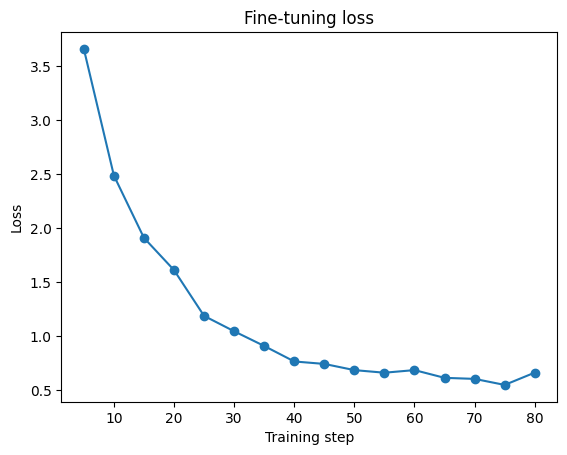

In [30]:
import matplotlib.pyplot as plt

# the trainer logs the loss every 5 steps
steps = [log["step"] for log in trainer.state.log_history if "loss" in log]
losses = [log["loss"] for log in trainer.state.log_history if "loss" in log]

for s, l in zip(steps, losses):
    print("Step", s, "loss", round(l, 4))

plt.plot(steps, losses, marker="o")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Fine-tuning loss")
plt.show()

## 7. Test the original and fine-tuned models with the same questions

In [31]:
# gradient checkpointing was only needed for training, turn it off so generation is normal and faster
model.gradient_checkpointing_disable()
model.config.use_cache = True
model.eval()

finetuned_answers = []
for question in test_questions:
    finetuned_answers.append(ask(model, question))

for i, question in enumerate(test_questions):
    print("Q:", question, "(in dataset)" if in_dataset[i] else "(new question)")
    print("Original:", original_answers[i])
    print("Fine-tuned:", finetuned_answers[i])
    print("=" * 60)

Q: How can a student get help with an assignment? (in dataset)
Original: As Qwen, I am here to assist you in any way that I can. Here are some steps that students can take to get help with their assignments:

1. Identify the problem: The first step is to identify what specific issue or question you need help with. This could be anything from understanding complex concepts to completing a particular task.

2. Research: Once you have identified your problem, research on the topic to find reliable sources of information and guidance. This will help you understand the subject matter better and provide you with a solid foundation for your work.

3. Seek feedback: Ask for feedback
Fine-tuned: A student can ask for guidance from lecturers or tutors, check the course syllabus and seek support online or in person.
Q: What should a student do if a group member is not contributing? (in dataset)
Original: If a group member is not contributing to the project or activities of the group, it's importa

In [32]:
import difflib
import pandas as pd

# for the questions in my dataset, how close is each answer to my dataset answer (0 to 1)
dataset_answers = {item["question"]: item["answer"] for item in data}

rows = []
for i, question in enumerate(test_questions):
    row = {
        "question": question,
        "in_dataset": in_dataset[i],
        "original_words": len(original_answers[i].split()),
        "finetuned_words": len(finetuned_answers[i].split()),
    }
    if in_dataset[i]:
        reference = dataset_answers[question]
        row["original_similarity"] = round(difflib.SequenceMatcher(None, original_answers[i], reference).ratio(), 2)
        row["finetuned_similarity"] = round(difflib.SequenceMatcher(None, finetuned_answers[i], reference).ratio(), 2)
    rows.append(row)

comparison = pd.DataFrame(rows)
comparison

,question,in_dataset,original_words,finetuned_words,original_similarity,finetuned_similarity
0,How can a student get help with an assignment?,True,105,21,0.17,0.58
1,What should a student do if a group member is ...,True,103,15,0.20,0.41
2,What should a student do if they cannot pay a ...,True,104,10,0.21,0.61
3,How can a student prepare for a group presenta...,False,100,23,NaN,NaN
4,What should a student do if they feel overwhel...,False,93,14,NaN,NaN
5,How can a student get a reference letter from ...,False,102,17,NaN,NaN


## Save the fine-tuned adapter

In [33]:
import os

model.save_pretrained("university_support_lora")
tokenizer.save_pretrained("university_support_lora")

# only the small LoRA adapter is saved, not the whole model
size = sum(os.path.getsize(os.path.join("university_support_lora", f)) for f in os.listdir("university_support_lora"))
print(os.listdir("university_support_lora"))
print("Folder size:", round(size / (1024 ** 2), 1), "MB")

['tokenizer.json', 'chat_template.jinja', 'adapter_model.safetensors', 'README.md', 'tokenizer_config.json', 'adapter_config.json']
Folder size: 13.0 MB
